In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from PIL import Image
from pathlib import Path
import torch
import clip
import torch.nn.functional as F

image_dir = Path("images")
names = ["astronaut", "cat", "coffee", "rocket"]
texts = [
    "a photo of an astronaut in a space suit",
    "a photo of a cat",
    "a photo of a cup of coffee",
    "a photo of a rocket launching into the sky"
]

images = [
    Image.open(image_dir / f"{name}.png").convert("RGB")
    for name in names
]

# 图片来源：scikit-image公开数据集

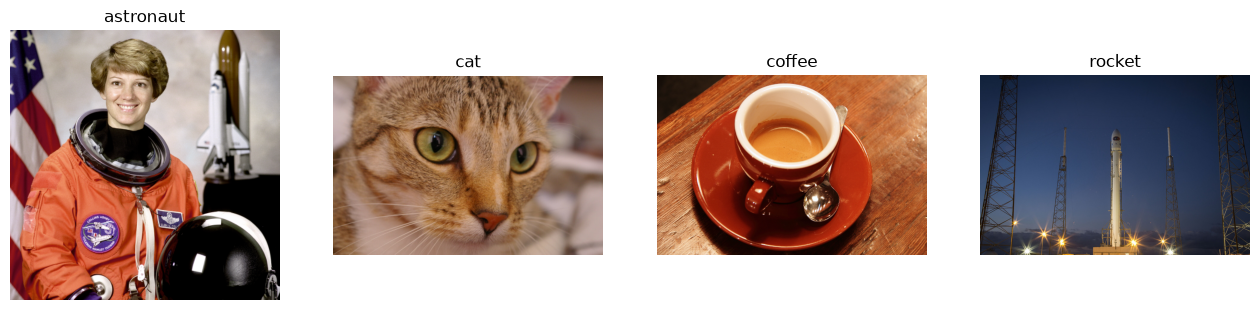

Image 1: a photo of an astronaut in a space suit
Image 2: a photo of a cat
Image 3: a photo of a cup of coffee
Image 4: a photo of a rocket launching into the sky


In [3]:
# 展示图片
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    axes[i].imshow(images[i])
    axes[i].set_title(names[i])
    axes[i].axis("off")

plt.show()

for i, text in enumerate(texts):
    print(f"Image {i + 1}: {text}")

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

model, preprocess = clip.load("RN50", device=device)
model.eval()

print("model: RN50")

device: cuda


D:\conda-envs\deep-learning\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


model: RN50


In [5]:
# 图像预处理
image_inputs = torch.stack([
    preprocess(img) for img in images
]).to(device)

# 文本Tokenization
text_inputs = clip.tokenize(texts).to(device)

print("Image inputs shape:", image_inputs.shape)
print("Text inputs shape:", text_inputs.shape)

Image inputs shape: torch.Size([4, 3, 224, 224])
Text inputs shape: torch.Size([4, 77])


In [6]:
# 提取特征
with torch.no_grad():
    image_features = model.encode_image(image_inputs)
    text_features = model.encode_text(text_inputs)

image_features = image_features.float()
text_features = text_features.float()

print("image features shape:", image_features.shape)
print("text features shape:", text_features.shape)

# L2归一化
image_features = F.normalize(image_features, p=2, dim=1)
text_features = F.normalize(text_features, p=2, dim=1)

image features shape: torch.Size([4, 1024])
text features shape: torch.Size([4, 1024])


In [7]:
# 计算所有图片与所有文本的余弦相似度
similarity = image_features @ text_features.T

similarity_np = similarity.cpu().numpy()

print("similarity shape:", similarity_np.shape)
print("similarity matrix:")
print(np.round(similarity_np, 4))

similarity shape: (4, 4)
similarity matrix:
[[0.2305 0.1075 0.1064 0.1183]
 [0.1277 0.2265 0.1425 0.1014]
 [0.1172 0.1549 0.2522 0.0811]
 [0.1546 0.1034 0.1067 0.2156]]


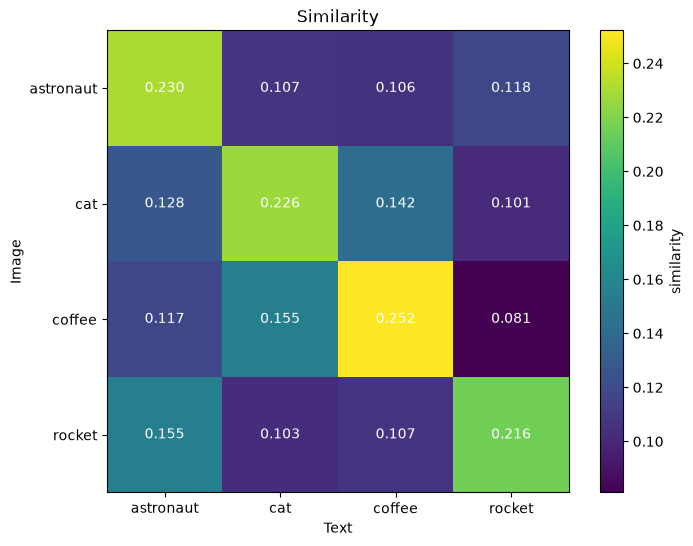

In [8]:
# 绘制相似度热力图
plt.figure(figsize=(8, 6))

plt.imshow(similarity_np, cmap="viridis")
plt.colorbar(label="similarity")

plt.xticks(range(4), names)
plt.yticks(range(4), names)

plt.xlabel("Text")
plt.ylabel("Image")
plt.title("Similarity")

for i in range(4):
    for j in range(4):
        plt.text(
            j, i,
            f"{similarity_np[i, j]:.3f}",
            ha="center",
            va="center",
            color="white"
        )

plt.show()

# 四张图片均配对成功，因为文本描述完全符合图片内容

In [11]:
# 错误描述：一杯咖啡改为一瓶牛奶
wrong_text = "a photo of a bottle of milk"
wrong_text_input = clip.tokenize([wrong_text]).to(device)

with torch.no_grad():
    wrong_text_feature = model.encode_text(wrong_text_input)

wrong_text_feature = F.normalize(
    wrong_text_feature.float(), p=2, dim=-1
)

correct_similarity = similarity_np[2, 2]

wrong_similarity = (
    image_features[2:3] @ wrong_text_feature.T
).item()

print("image:", names[2])
print("correct text:", texts[2])
print("wrong text:", wrong_text)

print("correct similarity:", correct_similarity)
print("wrong similarity:", wrong_similarity)

image: coffee
correct text: a photo of a cup of coffee
wrong text: a photo of a bottle of milk
correct similarity: 0.25217786
wrong similarity: 0.1724102944135666


# 修正：改变描述后能区分，相似度从0.25降为0.17